# Análisis exploratorio de datos

Exploración inicial del dataset de precios de vivienda. El objetivo es entender la distribución de la variable target (`SalePrice`) y las características de las variables explicativas antes de la etapa de limpieza y modelado.

## 1. Librerías

Carga de las librerías del ecosistema PyData utilizadas en el análisis y configuración general de visualización.

In [1]:
# Librerías PyData
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Carga de datos

Lectura de los datasets de entrenamiento y prueba. La ubicación de los archivos se define mediante `DATA_DIR`, `TRAIN_FILE` y `TEST_FILE`; si la fuente cambia, basta con actualizar estas variables.

In [2]:
# Carga de datos: ajustar DATA_DIR / nombres de archivo si cambia la fuente
from pathlib import Path

from house_pricing_a.config import RAW_DATA_DIR

DATA_DIR = Path(RAW_DATA_DIR)  # por ahora: data/raw/
TRAIN_FILE = "train.csv"
TEST_FILE = "test.csv"


def load_dataset(data_dir: Path, file_name: str) -> pd.DataFrame:
    path = data_dir / file_name
    if not path.exists():
        raise FileNotFoundError(f"No se encontró el archivo: {path}")
    return pd.read_csv(path)


train = load_dataset(DATA_DIR, TRAIN_FILE)
test = load_dataset(DATA_DIR, TEST_FILE)

print(f"train: {train.shape}")
print(f"test:  {test.shape}")

2026-10-27 19:36:43.856 | INFO     | house_pricing_a.config:<module>:11 - PROJ_ROOT path is: /Users/prengbiba/Dropbox/Compu/Clases/Postgrado/PAPD/L/Data Product Development/2026/house_pricing_A


train: (1460, 81)
test:  (1459, 80)


## 3. Análisis de la variable target: `SalePrice`

Gráfica de densidad del precio de venta para evaluar la forma de su distribución. Se incluyen la media y la mediana como referencia: una diferencia marcada entre ambas indica asimetría.

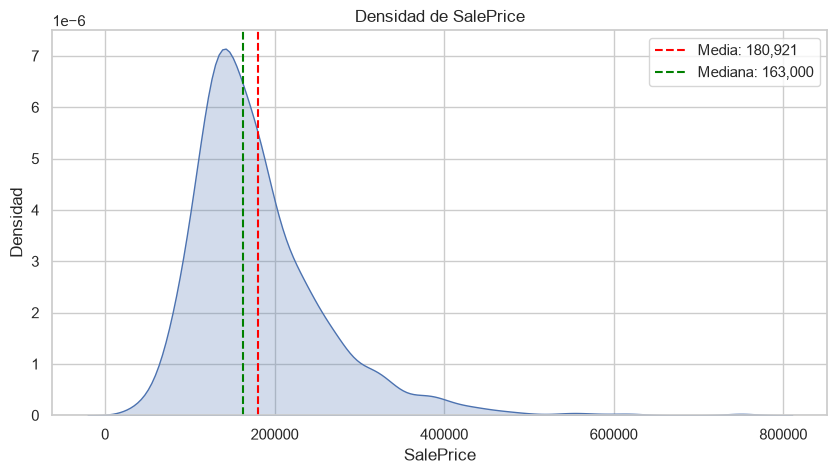

In [3]:
# Variable target: densidad de SalePrice
TARGET = "SalePrice"

fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(data=train, x=TARGET, fill=True, ax=ax)
ax.axvline(train[TARGET].mean(), color="red", linestyle="--", label=f"Media: {train[TARGET].mean():,.0f}")
ax.axvline(train[TARGET].median(), color="green", linestyle="--", label=f"Mediana: {train[TARGET].median():,.0f}")
ax.set_title(f"Densidad de {TARGET}")
ax.set_xlabel(TARGET)
ax.set_ylabel("Densidad")
ax.legend()
plt.show()

## 4. Clasificación de variables numéricas

Separación de las variables numéricas en dos grupos según su número de valores únicos:

- **Discretas:** hasta `MAX_UNIQUE_DISCRETE` valores únicos (conteos, calificaciones, meses, años de venta, códigos).
- **Continuas:** el resto.

Se excluye `Id` por ser un identificador.

In [6]:
# Clasificación de variables numéricas en discretas y continuas
MAX_UNIQUE_DISCRETE = 15

numeric_cols = (
    train.select_dtypes(include="number")
    .columns.drop([TARGET, "Id"], errors="ignore")
)
n_unique = train[numeric_cols].nunique()

discretas = n_unique[n_unique <= MAX_UNIQUE_DISCRETE].index.tolist()
continuas = n_unique[n_unique > MAX_UNIQUE_DISCRETE].index.tolist()

print(f"Discretas ({len(discretas)}): {discretas}")
print(f"Continuas ({len(continuas)}): {continuas}")

Discretas (15): ['MSSubClass', 'OverallQual', 'OverallCond', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'PoolArea', 'MoSold', 'YrSold']
Continuas (21): ['LotFrontage', 'LotArea', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageYrBlt', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'MiscVal']


## 5. Variables continuas vs `SalePrice`

Scatter plot de cada variable continua contra el target para identificar relaciones lineales, no lineales y posibles outliers. El título de cada gráfica incluye el coeficiente de correlación de Pearson con `SalePrice`.

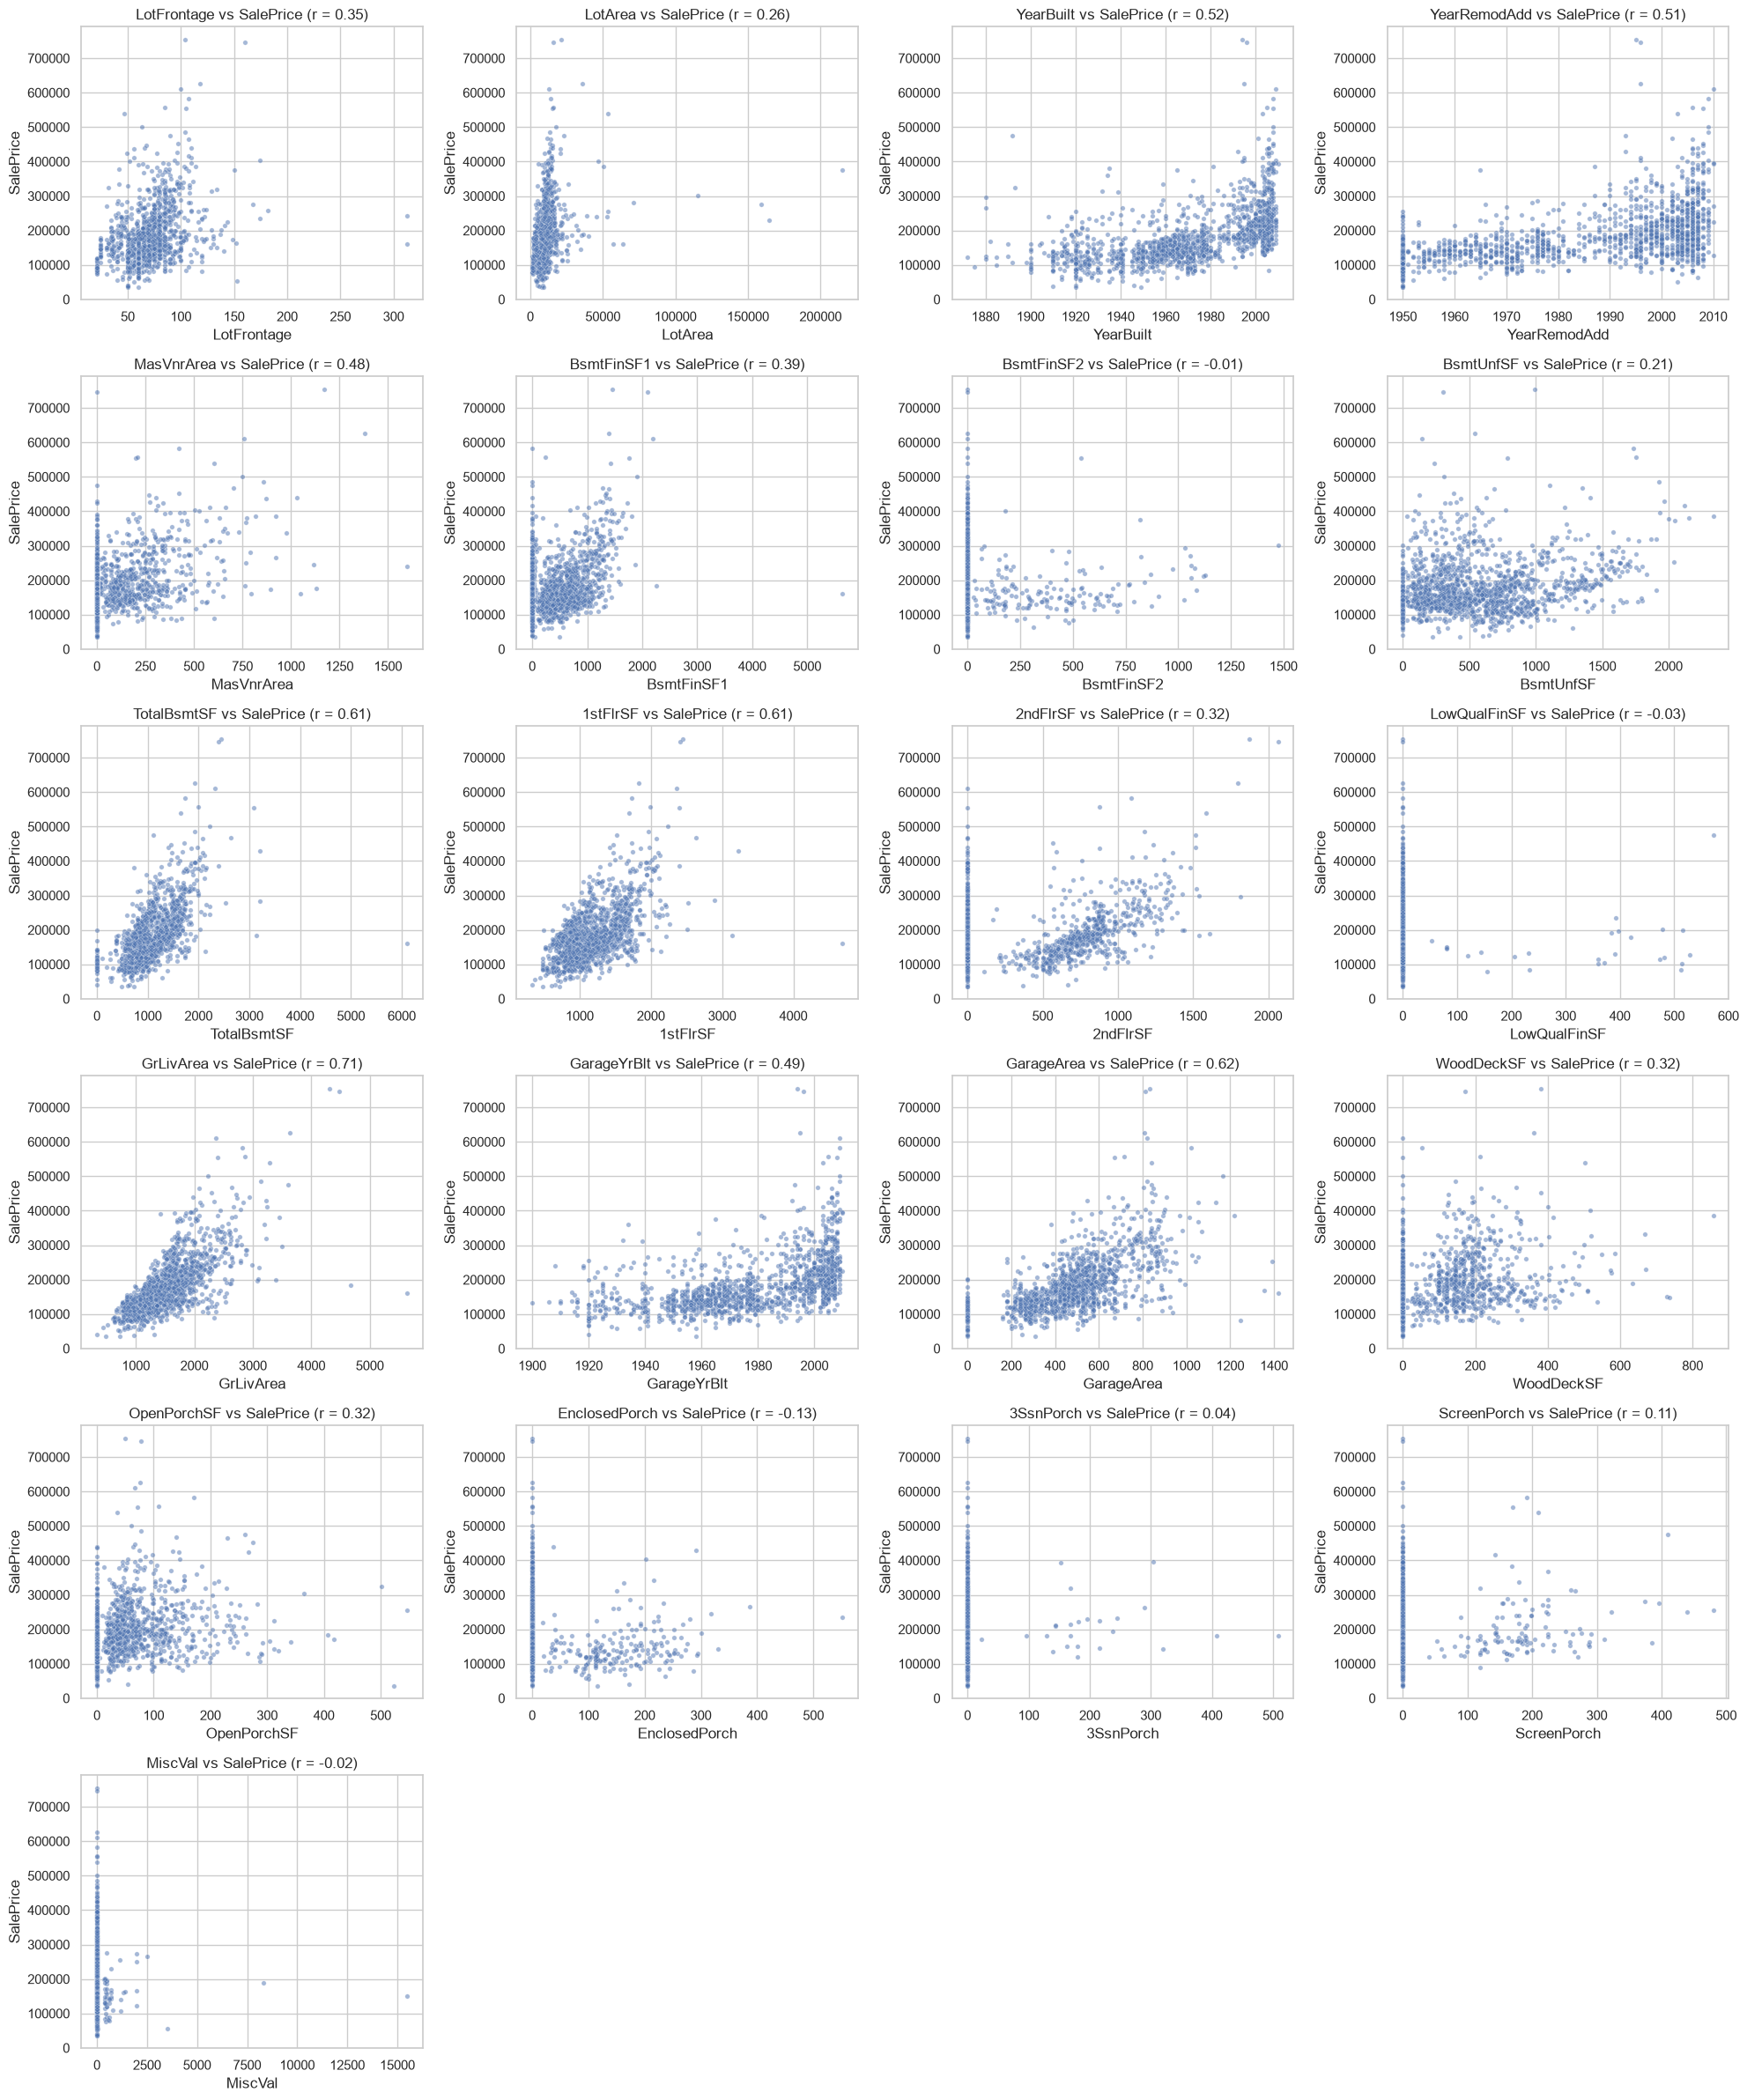

In [7]:
# Scatter plots: variables continuas vs SalePrice
n_cols = 4
n_rows = int(np.ceil(len(continuas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten()

correlations = {}
for ax, col in zip(axes, continuas):
    corr = train[col].corr(train[TARGET])
    correlations[col] = corr
    sns.scatterplot(data=train, x=col, y=TARGET, alpha=0.5, s=15, ax=ax)
    ax.set_title(f"{col} vs {TARGET} (r = {corr:.2f})")

# Ocultar ejes sobrantes de la grilla
for ax in axes[len(continuas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### 5.1 Ranking de correlaciones

Coeficientes de correlación de Pearson de cada variable continua con `SalePrice`, ordenados de mayor a menor.

In [8]:
# Ranking de correlaciones con SalePrice
corr_df = (
    pd.DataFrame.from_dict(correlations, orient="index", columns=["correlacion"])
    .rename_axis("variable")
    .sort_values("correlacion", ascending=False)
    .reset_index()
)
corr_df

,variable,correlacion
0,GrLivArea,0.708624
1,GarageArea,0.623431
2,TotalBsmtSF,0.613581
3,1stFlrSF,0.605852
4,YearBuilt,0.522897
5,YearRemodAdd,0.507101
6,GarageYrBlt,0.486362
7,MasVnrArea,0.477493
8,BsmtFinSF1,0.386420
9,LotFrontage,0.351799


## 6. Variables discretas vs `SalePrice`

Boxplot del target para cada valor de las variables discretas, con los puntos individuales superpuestos (stripplot con jitter). Permite comparar la mediana y dispersión del precio entre niveles, así como el volumen de observaciones en cada uno.

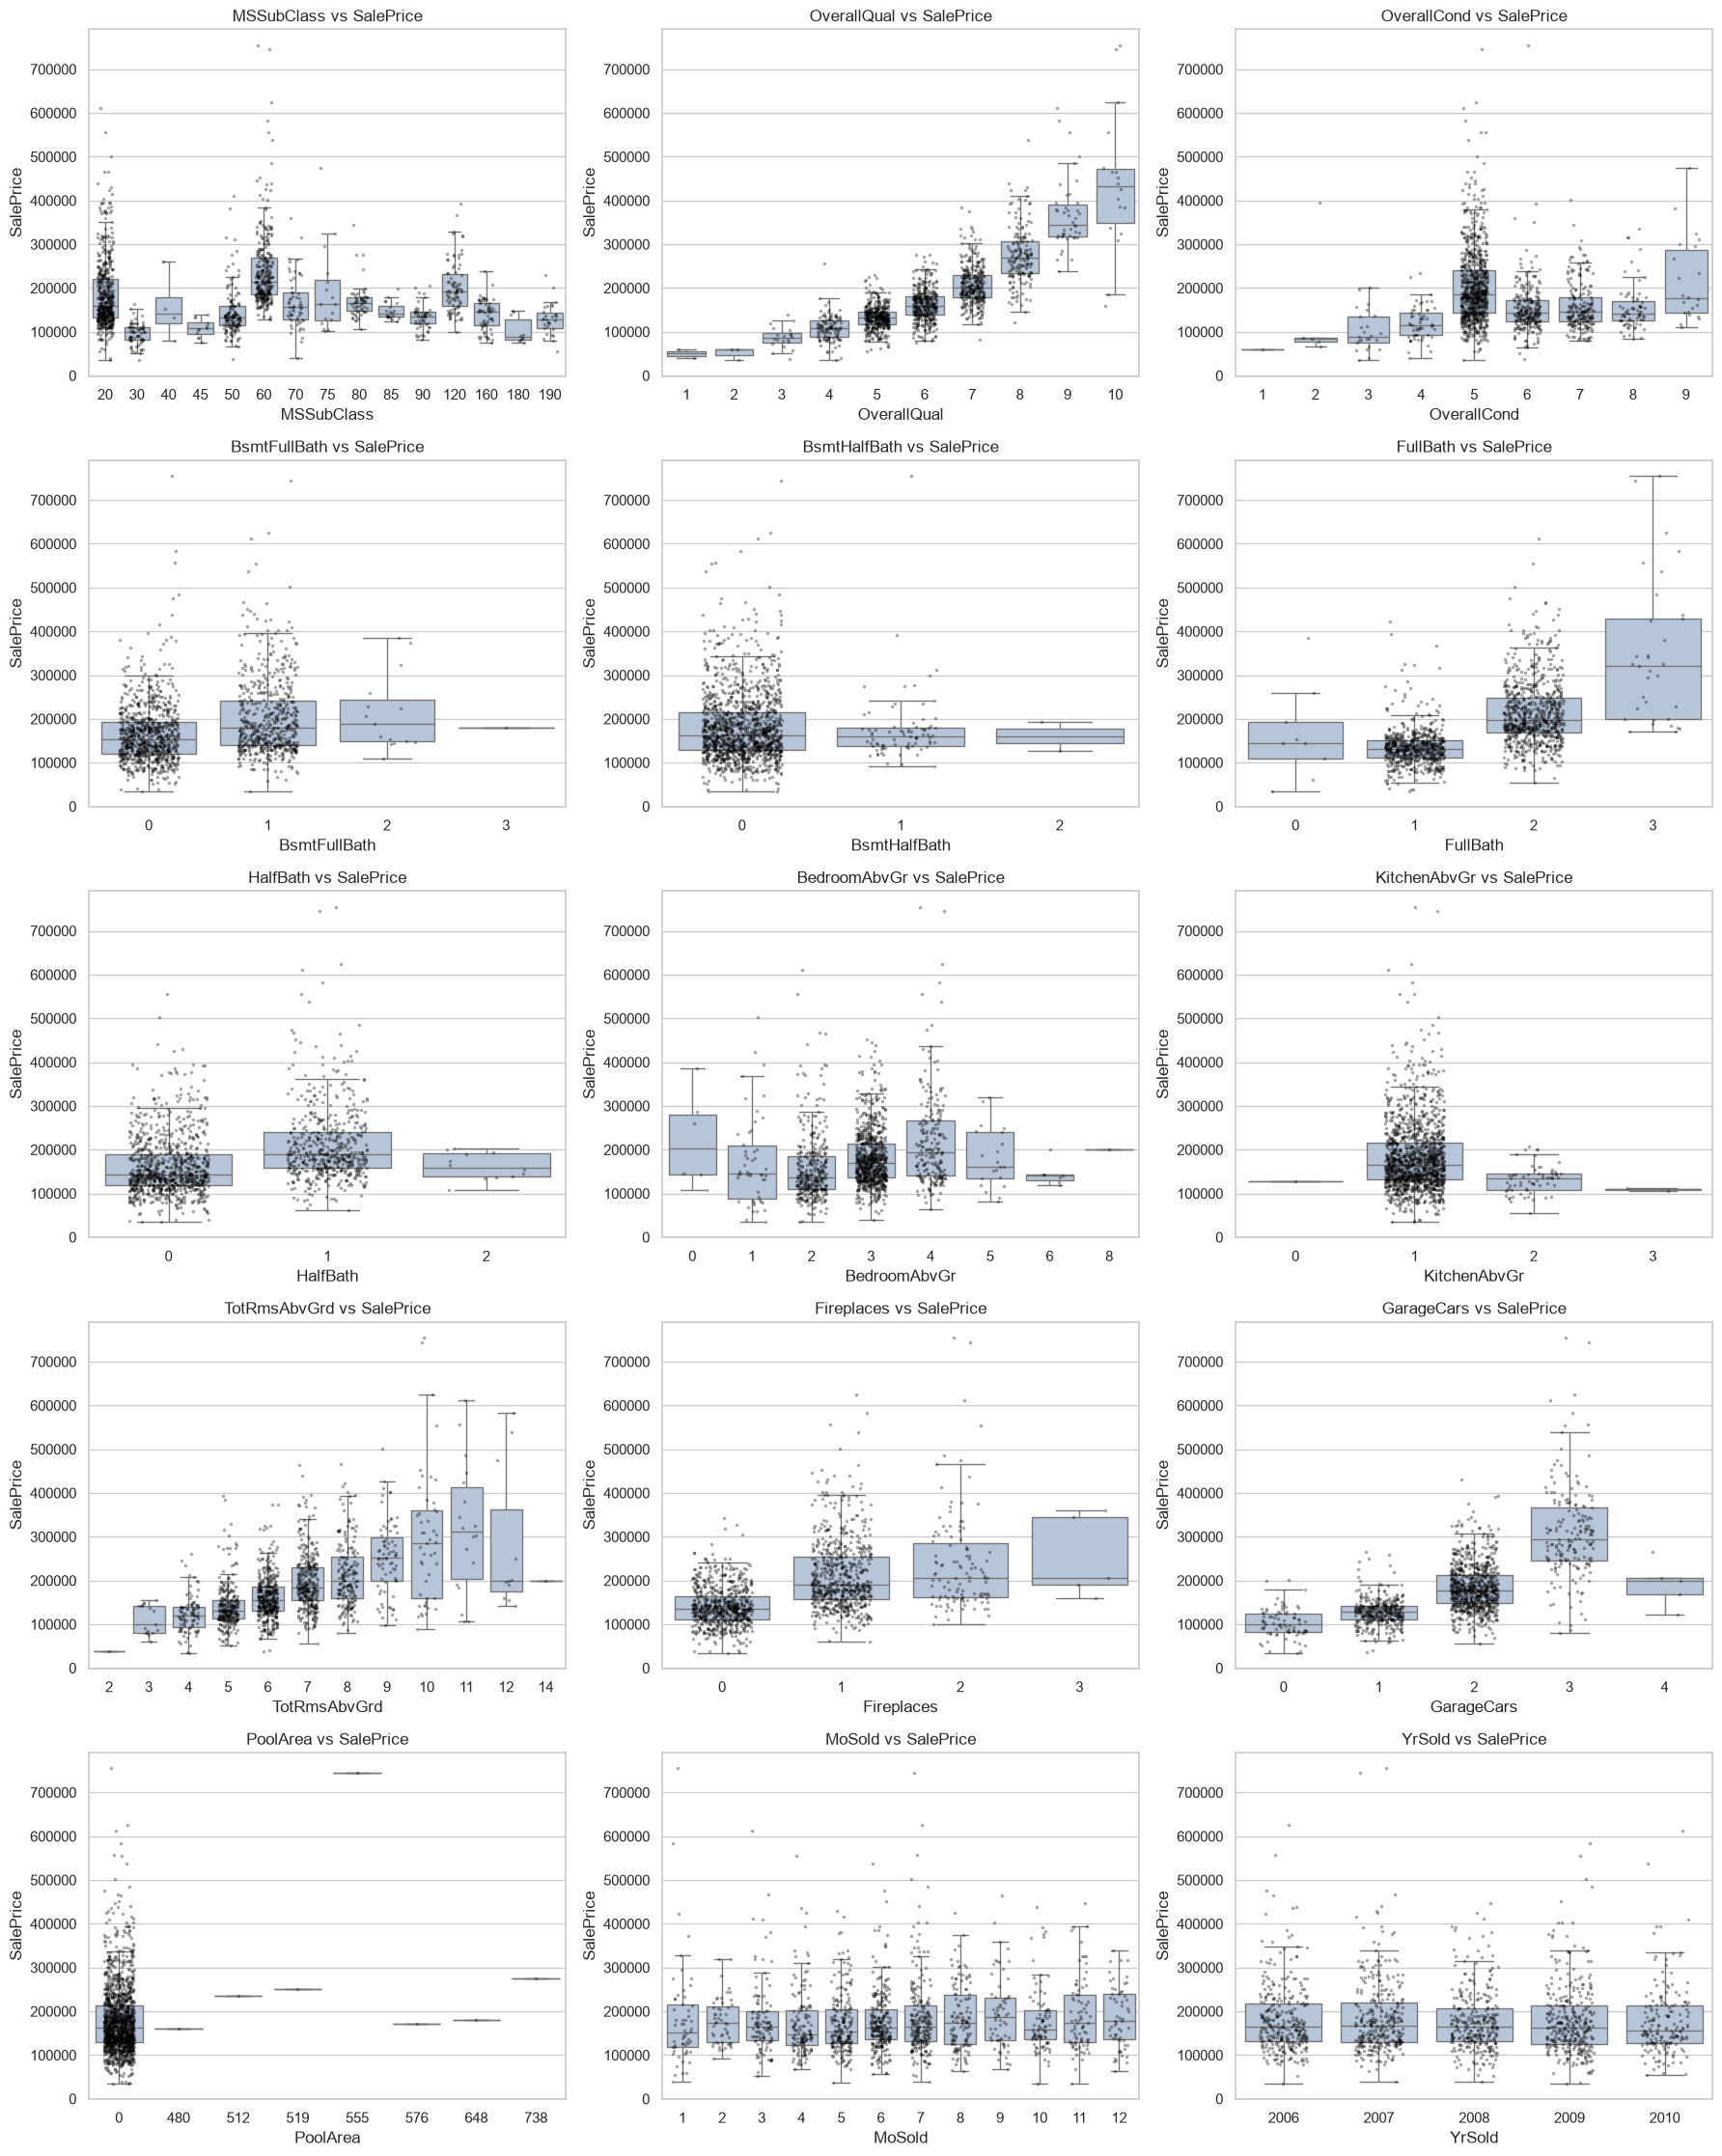

In [9]:
# Boxplots con puntos: variables discretas vs SalePrice
n_cols = 3
n_rows = int(np.ceil(len(discretas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.5 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, discretas):
    sns.boxplot(data=train, x=col, y=TARGET, showfliers=False, color="lightsteelblue", ax=ax)
    sns.stripplot(data=train, x=col, y=TARGET, jitter=0.25, alpha=0.35, size=2.5, color="black", ax=ax)
    ax.set_title(f"{col} vs {TARGET}")

# Ocultar ejes sobrantes de la grilla
for ax in axes[len(discretas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 7. Variables categóricas vs `SalePrice`

Boxplot del target para cada categoría, con los puntos individuales superpuestos. Las categorías se ordenan por mediana de `SalePrice` para facilitar la lectura.

Como medida de asociación se utiliza la **razón de correlación η (eta)**, análoga a la correlación de Pearson para una variable categórica frente a una numérica:

$$\eta = \sqrt{\frac{SS_{entre}}{SS_{total}}} = \sqrt{\frac{\sum_{k} n_k (\bar{y}_k - \bar{y})^2}{\sum_{i} (y_i - \bar{y})^2}}$$

- $\bar{y}_k$ y $n_k$: media de `SalePrice` y número de observaciones en la categoría $k$.
- $\bar{y}$: media global de `SalePrice`.
- Rango de 0 (las categorías no explican el precio) a 1 (el precio queda determinado por la categoría). $\eta^2$ es la proporción de varianza de `SalePrice` explicada por la variable (equivale al $R^2$ de un ANOVA de un factor).

Los valores faltantes se tratan como una categoría propia (`NA`), ya que en este dataset indican ausencia de la característica (sin garage, sin sótano, sin piscina, etc.).

In [11]:
# Razón de correlación (eta) entre una variable categórica y una numérica
def correlation_ratio(categories: pd.Series, values: pd.Series) -> float:
    y_mean = values.mean()
    groups = values.groupby(categories)
    ss_between = (groups.count() * (groups.mean() - y_mean) ** 2).sum()
    ss_total = ((values - y_mean) ** 2).sum()
    return np.sqrt(ss_between / ss_total)


categoricas = train.select_dtypes(exclude="number").columns.tolist()
train_cat = train[categoricas].fillna("NA")

print(f"Categóricas ({len(categoricas)}): {categoricas}")

Categóricas (43): ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


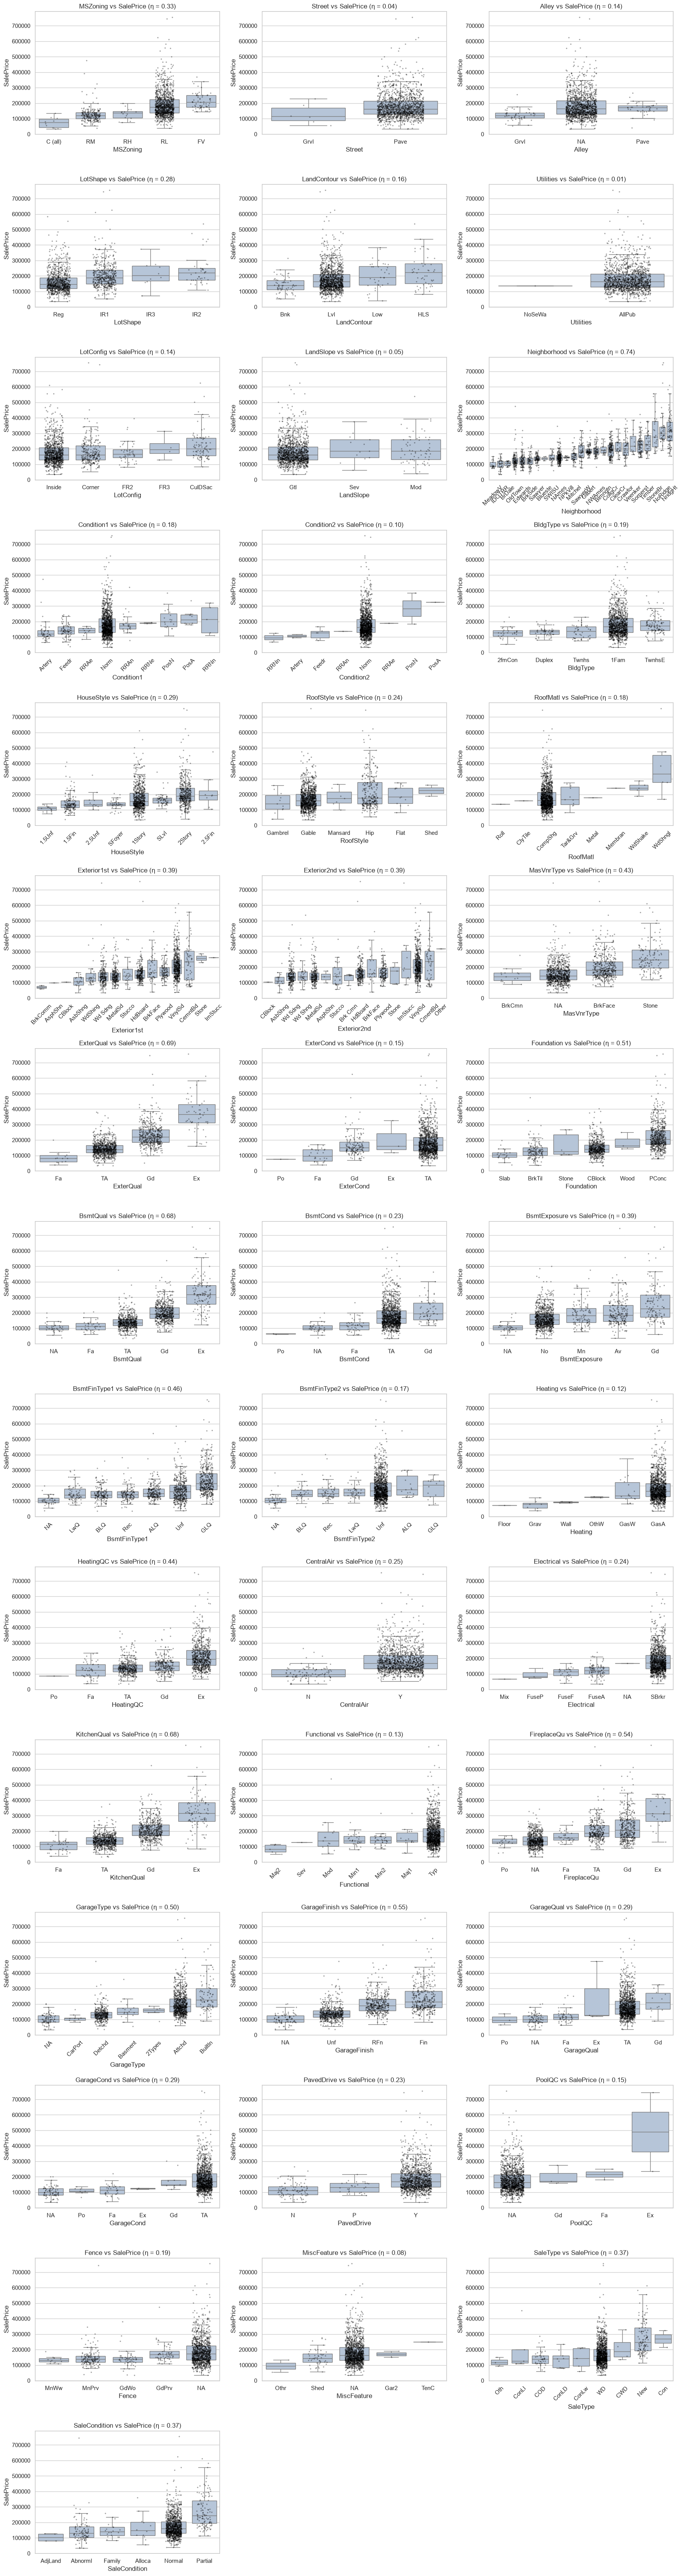

In [12]:
# Boxplots con puntos: variables categóricas vs SalePrice
n_cols = 3
n_rows = int(np.ceil(len(categoricas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.5 * n_rows))
axes = axes.flatten()

etas = {}
for ax, col in zip(axes, categoricas):
    eta = correlation_ratio(train_cat[col], train[TARGET])
    etas[col] = eta
    order = train[TARGET].groupby(train_cat[col]).median().sort_values().index
    sns.boxplot(x=train_cat[col], y=train[TARGET], order=order, showfliers=False, color="lightsteelblue", ax=ax)
    sns.stripplot(x=train_cat[col], y=train[TARGET], order=order, jitter=0.25, alpha=0.35, size=2.5, color="black", ax=ax)
    ax.set_title(f"{col} vs {TARGET} (η = {eta:.2f})")
    ax.tick_params(axis="x", rotation=45 if len(order) > 6 else 0)

# Ocultar ejes sobrantes de la grilla
for ax in axes[len(categoricas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### 7.1 Ranking de razón de correlación

Valores de η de cada variable categórica con `SalePrice`, ordenados de mayor a menor. Se incluye el número de categorías, ya que η tiende a aumentar con variables de muchas categorías poco pobladas.

In [13]:
# Ranking de eta con SalePrice
eta_df = (
    pd.DataFrame.from_dict(etas, orient="index", columns=["eta"])
    .assign(n_categorias=train_cat.nunique())
    .rename_axis("variable")
    .sort_values("eta", ascending=False)
    .reset_index()
)
eta_df

,variable,eta,n_categorias
0,Neighborhood,0.738630,25
1,ExterQual,0.690933,4
2,BsmtQual,0.681905,5
3,KitchenQual,0.675721,4
4,GarageFinish,0.553059,4
5,FireplaceQu,0.542181,6
6,Foundation,0.506328,6
7,GarageType,0.499204,7
8,BsmtFinType1,0.459141,7
9,HeatingQC,0.442154,5


## 8. Selección de features

Selección de las `TOP_N` variables con mayor asociación con `SalePrice` en cada grupo:

| Grupo | Métrica | Criterio |
|---|---|---|
| Continuas | Correlación de Pearson (r) | Mayor valor absoluto de r |
| Discretas | Razón de correlación (η) | Mayor η |
| Categóricas | Razón de correlación (η) | Mayor η |

Para las discretas se utiliza η en lugar de r porque algunas son códigos sin orden numérico real (`MSSubClass`, `MoSold`) y η captura relaciones no monótonas. El resultado se almacena en la lista `modelo_features`.

In [15]:
# Selección del top N de variables por grupo
TOP_N = 10

# Continuas: mayor |r| de Pearson
top_continuas = (
    corr_df.assign(abs_corr=corr_df["correlacion"].abs())
    .nlargest(TOP_N, "abs_corr")["variable"]
    .tolist()
)

# Discretas: mayor eta
eta_discretas_df = (
    pd.Series({col: correlation_ratio(train[col], train[TARGET]) for col in discretas}, name="eta")
    .rename_axis("variable")
    .sort_values(ascending=False)
    .reset_index()
)
top_discretas = eta_discretas_df.head(TOP_N)["variable"].tolist()

# Categóricas: mayor eta
top_categoricas = eta_df.head(TOP_N)["variable"].tolist()

modelo_features = top_continuas + top_discretas + top_categoricas

pd.DataFrame({
    "continuas": top_continuas,
    "discretas": top_discretas,
    "categoricas": top_categoricas,
}, index=range(1, TOP_N + 1))

,continuas,discretas,categoricas
1,GrLivArea,OverallQual,Neighborhood
2,GarageArea,GarageCars,ExterQual
3,TotalBsmtSF,FullBath,BsmtQual
4,1stFlrSF,TotRmsAbvGrd,KitchenQual
5,YearBuilt,MSSubClass,GarageFinish
6,YearRemodAdd,Fireplaces,FireplaceQu
7,GarageYrBlt,OverallCond,Foundation
8,MasVnrArea,HalfBath,GarageType
9,BsmtFinSF1,BedroomAbvGr,BsmtFinType1
10,LotFrontage,BsmtFullBath,HeatingQC


### 8.1 Guardado de la configuración

Persistencia de `modelo_features` en `pipeline_config.yaml`, en la raíz del proyecto, bajo la llave `MODEL_FEATURES`. Si el archivo ya existe, se actualiza únicamente esta llave y se conservan las demás.

In [16]:
# Guardar MODEL_FEATURES en pipeline_config.yaml
import yaml

from house_pricing_a.config import PROJ_ROOT

PIPELINE_CONFIG_PATH = PROJ_ROOT / "pipeline_config.yaml"

pipeline_config = {}
if PIPELINE_CONFIG_PATH.exists():
    with open(PIPELINE_CONFIG_PATH) as f:
        pipeline_config = yaml.safe_load(f) or {}

pipeline_config["MODEL_FEATURES"] = modelo_features

with open(PIPELINE_CONFIG_PATH, "w") as f:
    yaml.safe_dump(pipeline_config, f, sort_keys=False, allow_unicode=True)

print(f"{len(modelo_features)} features guardadas en {PIPELINE_CONFIG_PATH}")

30 features guardadas en /Users/prengbiba/Dropbox/Compu/Clases/Postgrado/PAPD/L/Data Product Development/2026/house_pricing_A/pipeline_config.yaml
